# Forecasting staple prices: seasonal naive, SARIMA and gradient boosting (#21, #22)

**Business question 5:** where are staple prices likely heading next year?

This notebook compares two models against the seasonal-naive baseline (#20): SARIMA (#21) and gradient boosting with lag features (#22). All three are scored on the same time-based validation. It covers the 8 agreed staples for Canada and the 10 provinces, 87 series in all.

- **Model:** SARIMA on log(price). For each series and training window, a small grid of orders is fitted and the one with the lowest AIC is kept.
- **Baseline:** seasonal naive, where the forecast is the price in the same month last year.
- **Validation:** rolling origin. Three folds, each trained only on data before a 12-month test year.

The model code lives in `models/sarima/sarima.py`, and this notebook reads its outputs. Set `RERUN = True` to refit everything, which takes about 5 minutes.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "models" / "sarima"))
import sarima

RERUN = False  # True refits every model (about 5 minutes)

OUT = ROOT / "models" / "sarima"
if RERUN or not (OUT / "sarima_metrics.csv").exists():
    sarima.run(verbose=False)

backtest = pd.read_csv(OUT / "sarima_backtest.csv", parse_dates=["date"])
metrics = pd.read_csv(OUT / "sarima_metrics.csv")
future = pd.read_csv(OUT / "sarima_forecasts.csv", parse_dates=["date"])
prices = sarima.load_prices()
print(f"{metrics[['province_code', 'product']].drop_duplicates().shape[0]} series, "
      f"{metrics['fold'].nunique()} folds")

Read 10,265 staple prices from data/raw/18100245_prices.csv
87 series, 3 folds


## Validation design

Each fold trains on every month up to its cut-off, then forecasts the next 12 months without seeing them. The orders are chosen again for every fold, so the test year never influences which model is picked.

| Fold | Trained up to | Test year |
|---|---|---|
| 1 | Sep 2023 | Oct 2023 to Sep 2024 |
| 2 | Sep 2024 | Oct 2024 to Sep 2025 |
| 3 | Sep 2025 | Oct 2025 to Sep 2026 (same holdout as the #20 baseline) |

The folds cover three different price regimes: inflation cooling after the 2022 to 2023 peak, a calmer year, and the latest year.

In [2]:
summary = (metrics.groupby(["fold", "model"])[["mae", "rmse", "mape_pct"]].mean()
           .unstack("model").round(2))
wide = metrics.pivot_table(index=["province_code", "product", "fold"], columns="model", values="rmse")
summary[("sarima wins", "% of series")] = ((wide["sarima"] < wide["seasonal_naive"])
                                           .groupby("fold").mean() * 100).round(0)
summary

mae                  rmse                mape_pct                 \
model sarima seasonal_naive sarima seasonal_naive   sarima seasonal_naive   
fold                                                                        
1       0.46           0.44   0.54           0.51     6.34           5.18   
2       0.36           0.65   0.45           0.74     4.23           6.79   
3       0.39           0.68   0.46           0.77     5.00           6.89   

      sarima wins  
model % of series  
fold               
1            36.0  
2            74.0  
3            75.0

## Canada, fold 3 (the baseline's holdout)

This is the same 12-month holdout used in `models/baseline/README.md`, so the seasonal-naive column should match that table.

In [3]:
ca3 = metrics.query("province_code == 'CA' and fold == 3").pivot_table(
    index="product", columns="model", values=["rmse", "mape_pct"]).round(2)
ca3[("rmse change %", "")] = ((ca3[("rmse", "sarima")] / ca3[("rmse", "seasonal_naive")] - 1) * 100).round(0)
ca3.sort_values(("rmse change %", ""))

mape_pct                  rmse  \
model                                 sarima seasonal_naive sarima   
product                                                              
Ground beef, per kilogram               1.94          12.01   0.38   
Milk, 4 litres                          1.41           3.02   0.11   
Chicken breasts, per kilogram           4.59           6.13   0.75   
Roasted or ground coffee, 340 grams    10.51          15.16   1.25   
White bread, 675 grams                  2.68           3.34   0.10   
Butter, 454 grams                       1.90           1.62   0.13   
Bananas, per kilogram                   6.92           7.81   0.16   
Eggs, 1 dozen                           6.18           1.76   0.31   

                                                   rmse change %  
model                               seasonal_naive                
product                                                           
Ground beef, per kilogram                     1.97         -81.0  
Milk, 4 litres                                0.21         -48.0  
Chicken breasts, per kilogram                 1.11         -32.0  
Roasted or ground coffee, 340 grams           1.71         -27.0  
White bread, 675 grams                        0.13         -23.0  
Butter, 454 grams                             0.15         -13.0  
Bananas, per kilogram                         0.17          -6.0  
Eggs, 1 dozen                                 0.10         210.0

## Error by staple, averaged over all folds and geographies

In [4]:
by_product = metrics.pivot_table(index="product", columns="model", values=["mape_pct", "rmse"]).round(2)
by_product[("sarima wins %", "")] = (wide["sarima"] < wide["seasonal_naive"]).groupby("product").mean().mul(100).round(0)
by_product.sort_values(("sarima wins %", ""), ascending=False)

mape_pct                  rmse  \
model                                 sarima seasonal_naive sarima   
product                                                              
Ground beef, per kilogram               3.82          12.59   0.64   
Milk, 4 litres                          1.46           2.74   0.12   
Chicken breasts, per kilogram           6.88           6.64   1.15   
Roasted or ground coffee, 340 grams     9.01          12.05   0.91   
White bread, 675 grams                  4.63           3.86   0.19   
Bananas, per kilogram                   3.98           3.98   0.09   
Eggs, 1 dozen                           5.53           4.28   0.30   
Butter, 454 grams                       5.89           3.84   0.41   

                                                   sarima wins %  
model                               seasonal_naive                
product                                                           
Ground beef, per kilogram                     1.90         100.0  
Milk, 4 litres                                0.21          87.0  
Chicken breasts, per kilogram                 1.24          70.0  
Roasted or ground coffee, 340 grams           1.22          67.0  
White bread, 675 grams                        0.16          52.0  
Bananas, per kilogram                         0.09          48.0  
Eggs, 1 dozen                                 0.25          45.0  
Butter, 454 grams                             0.29          24.0

## Canada: history, fold 3 backtest and next-12-month forecast

The black line is the actual price. The dashed lines are the fold 3 backtests, and the shaded band is the 80% interval on SARIMA's forecast for the next 12 months.

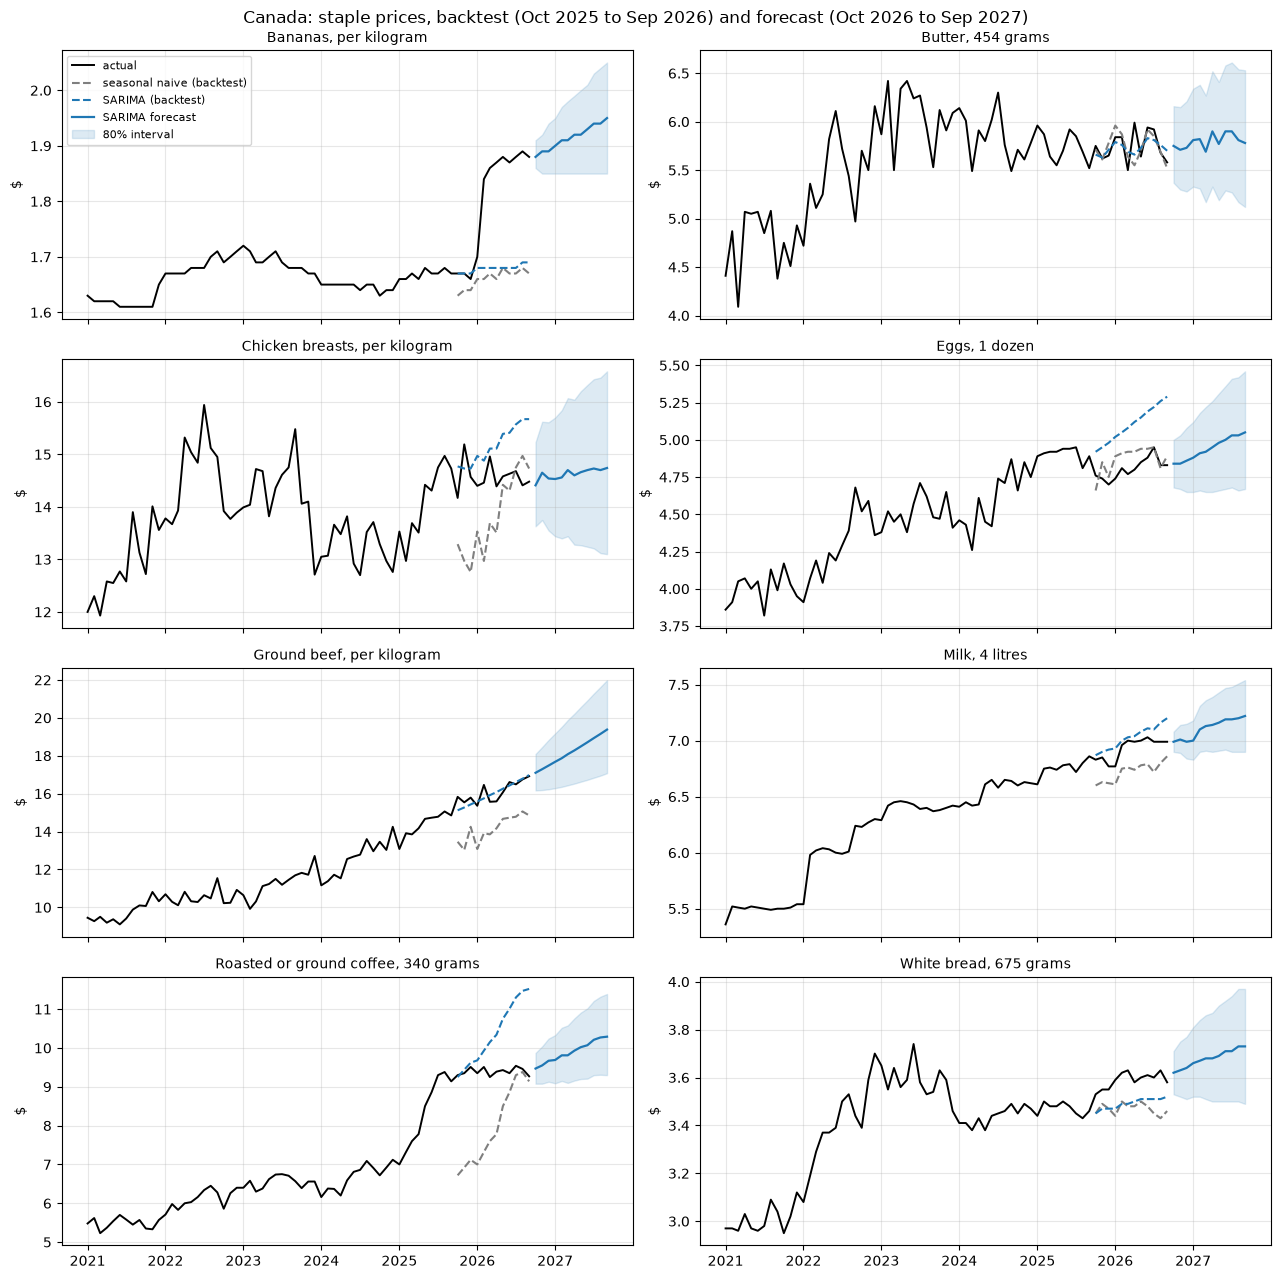

In [5]:
ca_hist = prices.query("province_code == 'CA' and date >= '2021-01-01'")
ca_bt = backtest.query("province_code == 'CA' and fold == 3")
ca_fc = future.query("province_code == 'CA'")

fig, axes = plt.subplots(4, 2, figsize=(13, 13), sharex=True)
for ax, (prod, hist) in zip(axes.flat, ca_hist.groupby("product")):
    bt, fc = ca_bt[ca_bt["product"] == prod], ca_fc[ca_fc["product"] == prod]
    ax.plot(hist["date"], hist["price"], color="black", lw=1.4, label="actual")
    ax.plot(bt["date"], bt["seasonal_naive"], color="tab:gray", ls="--", label="seasonal naive (backtest)")
    ax.plot(bt["date"], bt["sarima"], color="tab:blue", ls="--", label="SARIMA (backtest)")
    ax.plot(fc["date"], fc["forecast"], color="tab:blue", lw=1.6, label="SARIMA forecast")
    ax.fill_between(fc["date"], fc["lower_80"], fc["upper_80"], color="tab:blue", alpha=0.15, label="80% interval")
    ax.set_title(prod, fontsize=10)
    ax.set_ylabel("$")
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Canada: staple prices, backtest (Oct 2025 to Sep 2026) and forecast (Oct 2026 to Sep 2027)")
fig.tight_layout()

## Forecast: Canada, Sep 2027 vs latest price

In [6]:
latest = prices.query("province_code == 'CA'").sort_values("date").groupby("product").last()["price"]
end = ca_fc.sort_values("date").groupby("product").last()
outlook = pd.DataFrame({
    "latest (Sep 2026)": latest,
    "forecast Sep 2027": end["forecast"],
    "80% interval": end["lower_80"].round(2).astype(str) + " to " + end["upper_80"].round(2).astype(str),
})
outlook["change %"] = ((outlook["forecast Sep 2027"] / outlook["latest (Sep 2026)"] - 1) * 100).round(1)
outlook.round(2).sort_values("change %", ascending=False)

,latest (Sep 2026),forecast Sep 2027,80% interval,change %
product,,,,
"Ground beef, per kilogram",16.92,19.38,17.08 to 21.99,14.5
"Roasted or ground coffee, 340 grams",9.27,10.29,9.3 to 11.39,11.0
"Eggs, 1 dozen",4.83,5.05,4.67 to 5.46,4.6
"White bread, 675 grams",3.58,3.73,3.49 to 3.97,4.2
"Bananas, per kilogram",1.88,1.95,1.85 to 2.05,3.7
"Butter, 454 grams",5.58,5.78,5.12 to 6.53,3.6
"Milk, 4 litres",6.99,7.22,6.9 to 7.54,3.3
"Chicken breasts, per kilogram",14.48,14.74,13.1 to 16.58,1.8


## SARIMA findings (#21)

1. **SARIMA beats the baseline in 2 of the 3 folds.** In folds 2 and 3 it lowers average MAPE from about 6.8% to 4.2% (fold 2) and 5.0% (fold 3), and it has the lower RMSE on about three quarters of the series.
2. **It loses in fold 1 (Oct 2023 to Sep 2024).** That fold was trained up to Sep 2023, just after the 2022 to 2023 inflation spike. The drift term carried that steep rise forward while prices were cooling, so a "same as last year" forecast did better. SARIMA wins on only 36% of series there.
3. **Trending staples gain the most.** Ground beef wins in every fold and geography (100%), milk in 87% and chicken breasts in 70%. For ground beef in Canada, fold 3 MAPE falls from 12.0% to 1.9%.
4. **Volatile or flat staples gain little.** Butter (24%), eggs (45%) and bananas (48%) do as well or better with the seasonal-naive forecast. In Canada, eggs get worse in fold 3 (MAPE from 1.8% to 6.2%).
5. **Both models miss sudden moves.** Bananas jumped about 10% in early 2026, and neither model saw it coming. For coffee, SARIMA beat the baseline but overshot: it carried the 2025 surge forward while prices levelled off.
6. **Outlook to Sep 2027 (Canada):** SARIMA expects ground beef (about $19.40/kg) and coffee (about $10.30) to keep rising, and the other staples to rise slightly. The 80% intervals are wide (ground beef: $17.10 to $22.00), so treat these as directions, not point predictions.

## SARIMA limits

- Three folds is a small sample of years, and the results depend on the regime. A model that assumes the trend continues does badly when inflation turns.
- The forecasts only use each series' own price history. Nothing in the model knows about tariffs, avian flu, weather or exchange rates.
- The territories are excluded because their data starts in Sep 2025, and so is milk 4 L in NL. That is the same scope as the baseline.
- AIC selection compares models only within the same differencing (d=1, D=0), and a seasonally differenced model was not tested separately.

# Model 3: gradient boosting with lag features (#22)

The model code lives in `models/gbm/gbm.py`. It is one global `HistGradientBoostingRegressor` trained on all 87 series together.

- **Direct multi-horizon:** each training row is an origin month T and a horizon h from 1 to 12. The target is the log change from T to T+h, so the trees predict a change and never need to extrapolate a price level.
- **Features (all known at T):** horizon, the target's calendar month, product, province, log changes over the last 1, 2, 3, 6 and 12 months, 3- and 12-month volatility, and the change from T to the same calendar month a year before T+h (the seasonal signal).
- **Intervals:** three quantile models (10th, 50th and 90th percentile). The median is the forecast.
- **No leakage:** for each fold, the model trains only on rows whose target month is on or before the cut-off. The hyperparameters were fixed up front, not tuned on the test years.

Refitting takes about 40 seconds.

In [7]:
sys.path.insert(0, str(ROOT / "models" / "gbm"))
import gbm

GBM_OUT = ROOT / "models" / "gbm"
if RERUN or not (GBM_OUT / "gbm_metrics.csv").exists():
    gbm.run(verbose=False)

gbm_backtest = pd.read_csv(GBM_OUT / "gbm_backtest.csv", parse_dates=["date"])
gbm_future = pd.read_csv(GBM_OUT / "gbm_forecasts.csv", parse_dates=["date"])
all_metrics = pd.concat([metrics, pd.read_csv(GBM_OUT / "gbm_metrics.csv")], ignore_index=True)
MODELS = ["seasonal_naive", "sarima", "gbm"]

## All three models by test year

These are average errors across the 87 series. "Best model share" is the share of series where each model has the lowest RMSE in that year.

In [8]:
by_fold = all_metrics.groupby(["fold", "model"])[["mae", "rmse", "mape_pct"]].mean().unstack("model")
by_fold = by_fold.reindex(columns=MODELS, level="model").round(2)
rmse_wide = all_metrics.pivot_table(index=["province_code", "product", "fold"], columns="model", values="rmse")[MODELS]
best_share = (pd.crosstab(rmse_wide.index.get_level_values("fold"), rmse_wide.idxmin(axis=1), normalize="index")
              .reindex(columns=MODELS) * 100).round(0)
best_share.columns = pd.MultiIndex.from_product([["best model share %"], best_share.columns])
best_share.index.name = "fold"
by_fold.join(best_share)

mae                        rmse                    mape_pct  \
     seasonal_naive sarima   gbm seasonal_naive sarima   gbm seasonal_naive   
fold                                                                          
1              0.44   0.46  0.39           0.51   0.54  0.47           5.18   
2              0.65   0.36  0.39           0.74   0.45  0.47           6.79   
3              0.68   0.39  0.32           0.77   0.46  0.37           6.89   

                  best model share %               
     sarima   gbm     seasonal_naive sarima   gbm  
fold                                               
1      6.34  4.95               40.0   18.0  41.0  
2      4.23  4.26               16.0   41.0  43.0  
3      5.00  4.04               16.0   38.0  46.0

## By staple, averaged over all folds and geographies

In [9]:
by_staple = all_metrics.pivot_table(index="product", columns="model", values=["rmse", "mape_pct"])
by_staple = by_staple.reindex(columns=MODELS, level="model").round(2)
by_staple[("best (MAPE)", "")] = by_staple["mape_pct"].idxmin(axis=1)
by_staple

mape_pct               \
model                               seasonal_naive sarima   gbm   
product                                                           
Bananas, per kilogram                         3.98   3.98  3.56   
Butter, 454 grams                             3.84   5.89  5.06   
Chicken breasts, per kilogram                 6.64   6.88  5.78   
Eggs, 1 dozen                                 4.28   5.53  3.84   
Ground beef, per kilogram                    12.59   3.82  5.46   
Milk, 4 litres                                2.74   1.46  1.32   
Roasted or ground coffee, 340 grams          12.05   9.01  6.32   
White bread, 675 grams                        3.86   4.63  3.73   

                                              rmse               \
model                               seasonal_naive sarima   gbm   
product                                                           
Bananas, per kilogram                         0.09   0.09  0.08   
Butter, 454 grams                             0.29   0.41  0.35   
Chicken breasts, per kilogram                 1.24   1.15  0.97   
Eggs, 1 dozen                                 0.25   0.30  0.21   
Ground beef, per kilogram                     1.90   0.64  0.94   
Milk, 4 litres                                0.21   0.12  0.12   
Roasted or ground coffee, 340 grams           1.22   0.91  0.66   
White bread, 675 grams                        0.16   0.19  0.15   

                                        best (MAPE)  
model                                                
product                                              
Bananas, per kilogram                           gbm  
Butter, 454 grams                    seasonal_naive  
Chicken breasts, per kilogram                   gbm  
Eggs, 1 dozen                                   gbm  
Ground beef, per kilogram                    sarima  
Milk, 4 litres                                  gbm  
Roasted or ground coffee, 340 grams             gbm  
White bread, 675 grams                          gbm

## Are the gradient-boosting intervals honest?

An 80% interval should contain the actual price in about 80% of backtest months.

In [10]:
inside = gbm_backtest["actual"].between(gbm_backtest["lower_80"], gbm_backtest["upper_80"])
(inside.groupby(gbm_backtest["fold"]).mean() * 100).round(0).rename("% of months inside the 80% interval").to_frame()

,% of months inside the 80% interval
fold,
1,70.0
2,83.0
3,72.0


## Canada: all three models on the latest test year, plus the gradient-boosting forecast

The dashed lines are the fold 3 backtests (Oct 2025 to Sep 2026). The solid green line is the gradient-boosting forecast to Sep 2027, with its 80% interval.

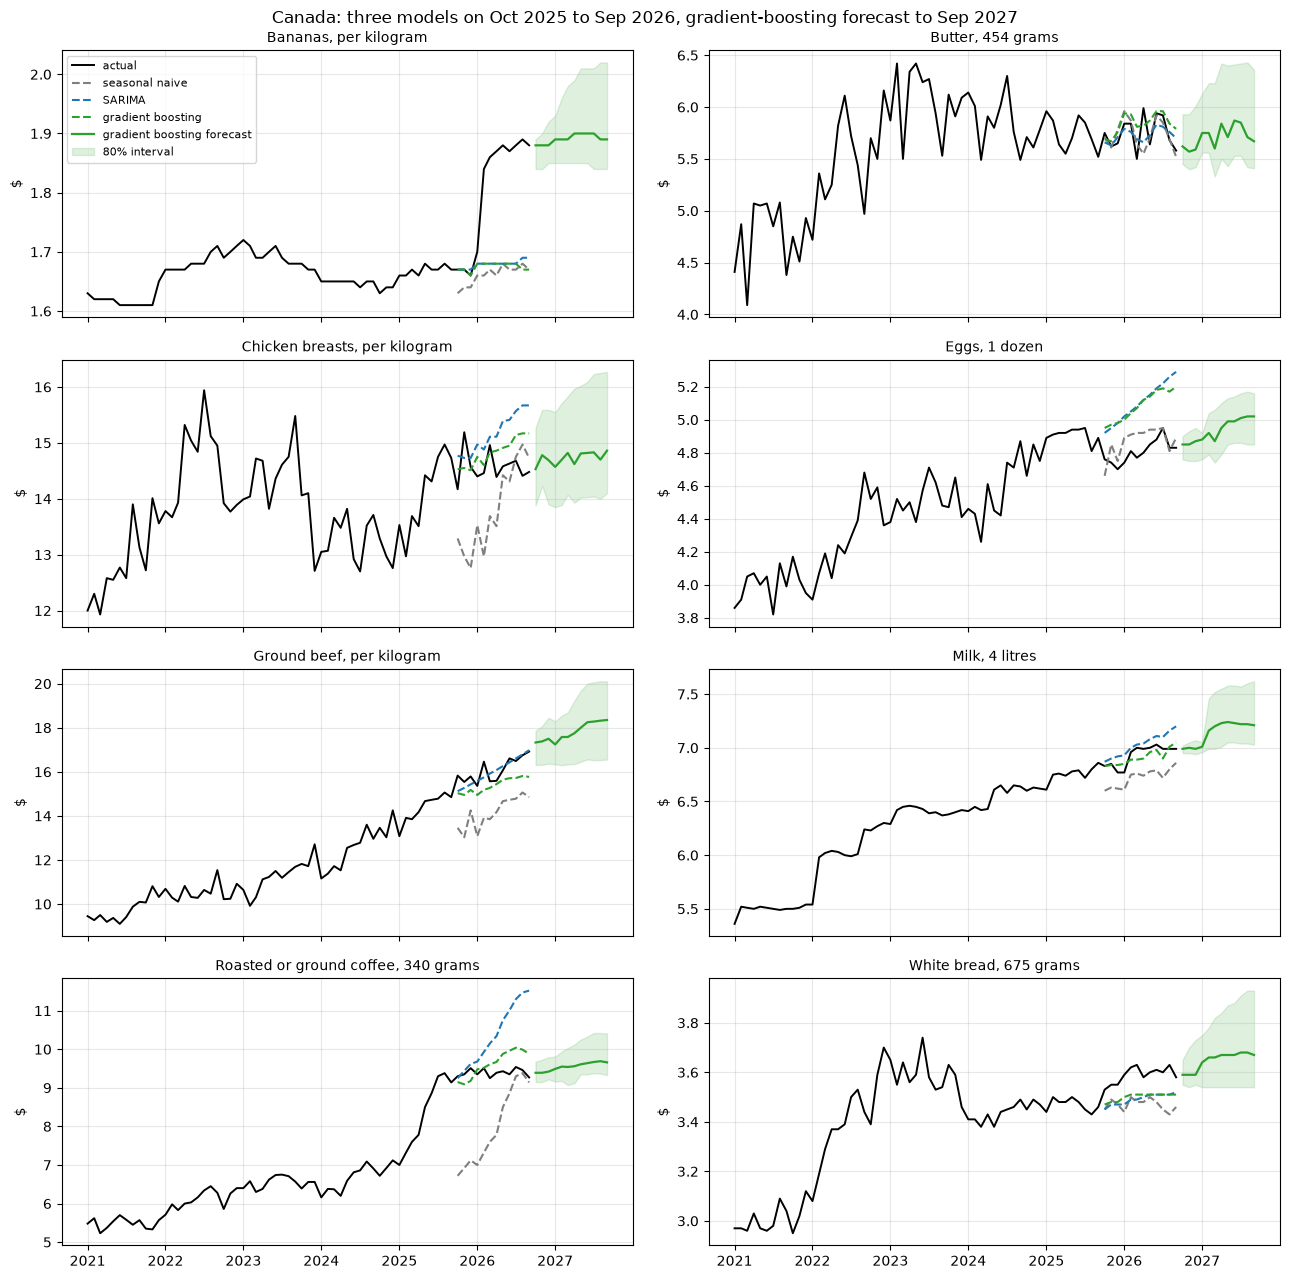

In [11]:
bt3 = (backtest.query("province_code == 'CA' and fold == 3")
       .merge(gbm_backtest.query("province_code == 'CA' and fold == 3")[["date", "product", "gbm"]], on=["date", "product"]))
gfc = gbm_future.query("province_code == 'CA'")

fig, axes = plt.subplots(4, 2, figsize=(13, 13), sharex=True)
for ax, (prod, hist) in zip(axes.flat, ca_hist.groupby("product")):
    bt, fc = bt3[bt3["product"] == prod], gfc[gfc["product"] == prod]
    ax.plot(hist["date"], hist["price"], color="black", lw=1.4, label="actual")
    ax.plot(bt["date"], bt["seasonal_naive"], color="tab:gray", ls="--", label="seasonal naive")
    ax.plot(bt["date"], bt["sarima"], color="tab:blue", ls="--", label="SARIMA")
    ax.plot(bt["date"], bt["gbm"], color="tab:green", ls="--", label="gradient boosting")
    ax.plot(fc["date"], fc["forecast"], color="tab:green", lw=1.6, label="gradient boosting forecast")
    ax.fill_between(fc["date"], fc["lower_80"], fc["upper_80"], color="tab:green", alpha=0.15, label="80% interval")
    ax.set_title(prod, fontsize=10)
    ax.set_ylabel("$")
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Canada: three models on Oct 2025 to Sep 2026, gradient-boosting forecast to Sep 2027")
fig.tight_layout()

## Outlook to Sep 2027 (Canada): gradient boosting vs SARIMA

In [12]:
g_end = gfc.sort_values("date").groupby("product").last()
s_end = ca_fc.sort_values("date").groupby("product").last()
compare = pd.DataFrame({
    "latest (Sep 2026)": latest,
    "gradient boosting": g_end["forecast"],
    "gb 80% interval": g_end["lower_80"].round(2).astype(str) + " to " + g_end["upper_80"].round(2).astype(str),
    "SARIMA": s_end["forecast"],
})
compare["gb change %"] = ((compare["gradient boosting"] / compare["latest (Sep 2026)"] - 1) * 100).round(1)
compare["SARIMA change %"] = ((compare["SARIMA"] / compare["latest (Sep 2026)"] - 1) * 100).round(1)
compare.round(2).sort_values("gb change %", ascending=False)

,latest (Sep 2026),gradient boosting,gb 80% interval,SARIMA,gb change %,SARIMA change %
product,,,,,,
"Ground beef, per kilogram",16.92,18.35,16.56 to 20.1,19.38,8.5,14.5
"Roasted or ground coffee, 340 grams",9.27,9.66,9.33 to 10.41,10.29,4.2,11.0
"Eggs, 1 dozen",4.83,5.02,4.85 to 5.16,5.05,3.9,4.6
"Milk, 4 litres",6.99,7.21,7.03 to 7.62,7.22,3.1,3.3
"Chicken breasts, per kilogram",14.48,14.86,14.1 to 16.27,14.74,2.6,1.8
"White bread, 675 grams",3.58,3.67,3.54 to 3.93,3.73,2.5,4.2
"Butter, 454 grams",5.58,5.67,5.41 to 6.36,5.78,1.6,3.6
"Bananas, per kilogram",1.88,1.89,1.84 to 2.02,1.95,0.5,3.7


## Gradient-boosting findings (#22)

1. **It is the most consistent model.** It has the lowest average RMSE in fold 1 (0.47 vs 0.54 for SARIMA and 0.51 for the baseline) and fold 3 (0.37 vs 0.46 and 0.77), and it comes a close second to SARIMA in fold 2 (0.47 vs 0.45). Its average MAPE stays between 4.0% and 5.0% in every test year. SARIMA ranges from 4.2% to 6.3%, and the baseline from 5.2% to 6.9%.
2. **It holds up in the year SARIMA lost.** In fold 1, the year after the inflation peak, it beats the baseline on 54% of series where SARIMA managed only 36%. It doesn't carry a fixed drift forward, so it didn't overshoot as much when prices cooled.
3. **The best model depends on the staple.** Gradient boosting is best for coffee (6.3% MAPE vs 9.0% for SARIMA and 12.1% for the baseline), chicken, eggs, bananas, milk and bread. SARIMA is still best for ground beef, which has a steady trend (3.8% vs 5.5%). The baseline is still best for butter.
4. **Its intervals are a little too narrow.** The 80% intervals contain the actual price in 70% to 83% of months depending on the year, so treat them as somewhat optimistic.
5. **It is more cautious than SARIMA about Sep 2027.** For Canada it expects ground beef around $18.35/kg (+8%, against SARIMA's +15%) and coffee around $9.66 (+4%, against +11%). The other staples move by only a few percent in either model.

## Gradient-boosting limits

- The hyperparameters were fixed, not tuned. Tuning against only three test years would mostly fit noise.
- Like SARIMA, it only sees each staple's own price history. Shocks from outside that history (tariffs, avian flu, weather, the exchange rate) are invisible to it.
- One pooled model means a province with unusual behaviour can pull the others slightly. With 87 series, pooling helps more than it hurts on these folds.
- The same exclusions apply as for the other models: the territories, and milk 4 L in NL.

## Proposal for the dashboard (#23)

Use gradient boosting as the headline forecast, with its 80% interval. Show the seasonal-naive baseline alongside as the "no change from last year" reference, and give the backtest MAPE for each staple so readers can see how much to trust each line.